In [1]:
import os, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE)

Device : cuda


1. Chargement et pré-traitement

In [2]:
CSV_NAME = "predictive_maintenance.csv"

def find_csv():
    candidates = [
        CSV_NAME,
        f"/content/{CSV_NAME}",
        f"/kaggle/input/machine-predictive-maintenance-classification/{CSV_NAME}",
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    try:
        import kagglehub
        path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
        return os.path.join(path, CSV_NAME)
    except Exception as e:
        raise FileNotFoundError(
            f"Placez {CSV_NAME} à côté du notebook (ou uploadez-le sur Colab). Détail : {e}")

df = pd.read_csv(find_csv())
print(df.shape)
df.head()

(10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [3]:
# Noms de colonnes plus simples (sans crochets ni espaces)
df = df.rename(columns={
    "Air temperature [K]": "Air_temp",
    "Process temperature [K]": "Process_temp",
    "Rotational speed [rpm]": "Rot_speed",
    "Torque [Nm]": "Torque",
    "Tool wear [min]": "Tool_wear",
    "Failure Type": "Failure_Type",
})
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   UDI           10000 non-null  int64  
 1   Product ID    10000 non-null  object 
 2   Type          10000 non-null  object 
 3   Air_temp      10000 non-null  float64
 4   Process_temp  10000 non-null  float64
 5   Rot_speed     10000 non-null  int64  
 6   Torque        10000 non-null  float64
 7   Tool_wear     10000 non-null  int64  
 8   Target        10000 non-null  int64  
 9   Failure_Type  10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [4]:
print("Valeurs manquantes :\n", df.isna().sum(), sep="")
print("\nDoublons :", df.duplicated().sum())
print("Doublons sur Product ID :", df["Product ID"].duplicated().sum())

Valeurs manquantes :
UDI             0
Product ID      0
Type            0
Air_temp        0
Process_temp    0
Rot_speed       0
Torque          0
Tool_wear       0
Target          0
Failure_Type    0
dtype: int64

Doublons : 0
Doublons sur Product ID : 0


In [5]:
display(pd.crosstab(df["Target"], df["Failure_Type"]))

Failure_Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Target,,,,,,
0,0,9643,0,0,18,0
1,112,9,78,95,0,45


In [6]:
bad = (df["Target"] == 1) & (df["Failure_Type"] == "No Failure")
print("Lignes incohérentes supprimées :", bad.sum())
df = df[~bad].reset_index(drop=True)

Lignes incohérentes supprimées : 9


In [7]:
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})
df["Temp_diff"] = df["Process_temp"] - df["Air_temp"]
df["Power"] = df["Torque"] * df["Rot_speed"] * 2 * np.pi / 60

FEATURES = ["Type", "Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear", "Temp_diff", "Power"]
NUM_FEATURES = [f for f in FEATURES if f != "Type"]
df = df.drop(columns=["UDI", "Product ID", "Target"])
df.head()

,Type,Air_temp,Process_temp,Rot_speed,Torque,Tool_wear,Failure_Type,Temp_diff,Power
0,1,298.1,308.6,1551,42.8,0,No Failure,10.5,6951.590560
1,0,298.2,308.7,1408,46.3,3,No Failure,10.5,6826.722724
2,0,298.1,308.5,1498,49.4,5,No Failure,10.4,7749.387543
3,0,298.2,308.6,1433,39.5,7,No Failure,10.4,5927.504659
4,0,298.2,308.7,1408,40.0,9,No Failure,10.5,5897.816608


In [8]:
# Détection des valeurs aberrantes (IQR) – on les CONSERVE : ce sont souvent les signaux de panne
rows = []
for c in NUM_FEATURES:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append({"feature": c, "outliers_IQR": n_out, "%": round(100 * n_out / len(df), 2)})
pd.DataFrame(rows)

,feature,outliers_IQR,%
0,Air_temp,0,0.00
1,Process_temp,0,0.00
2,Rot_speed,418,4.18
3,Torque,70,0.70
4,Tool_wear,0,0.00
5,Temp_diff,0,0.00
6,Power,61,0.61


2. Analyse exploratoire (EDA)

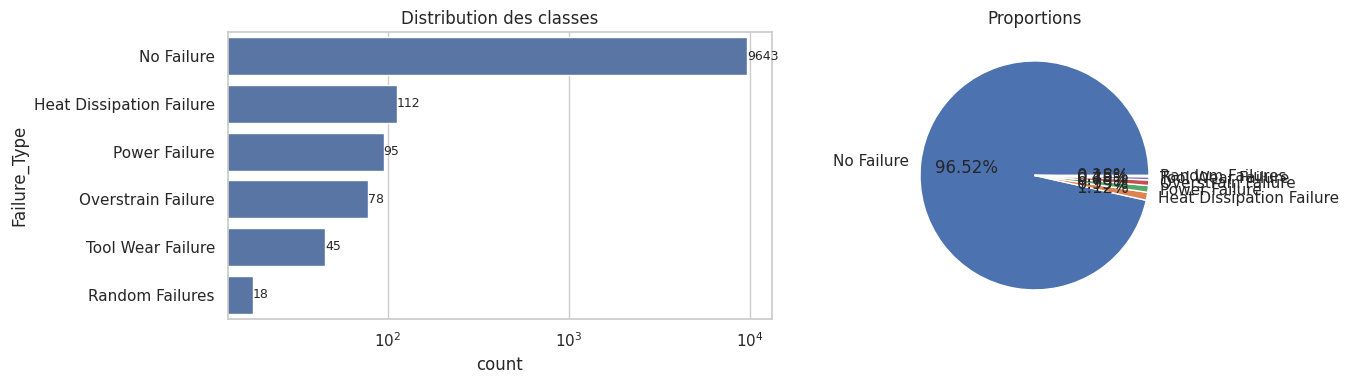

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = df["Failure_Type"].value_counts().index
sns.countplot(data=df, y="Failure_Type", order=order, ax=ax[0])
ax[0].set_title("Distribution des classes"); ax[0].set_xscale("log")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_width()), (p.get_width(), p.get_y() + p.get_height() / 2),
                   va="center", ha="left", fontsize=9)
df["Failure_Type"].value_counts().plot.pie(autopct="%.2f%%", ax=ax[1], ylabel="")
ax[1].set_title("Proportions")
plt.tight_layout(); plt.show()

In [10]:
df[NUM_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Air_temp,9991.0,300.004634,2.000300,295.30000,298.300000,300.100000,301.500000,304.500000
Process_temp,9991.0,310.005385,1.483990,305.70000,308.800000,310.100000,311.100000,313.800000
Rot_speed,9991.0,1538.804124,179.321027,1168.00000,1423.000000,1503.000000,1612.000000,2886.000000
Torque,9991.0,39.985377,9.969029,3.80000,33.200000,40.100000,46.700000,76.600000
Tool_wear,9991.0,107.942648,63.656648,0.00000,53.000000,108.000000,162.000000,253.000000
Temp_diff,9991.0,10.000751,1.001110,7.60000,9.300000,9.800000,11.000000,12.100000
Power,9991.0,6279.588528,1067.414568,1148.44061,5561.477699,6269.540323,7002.788048,10469.923005


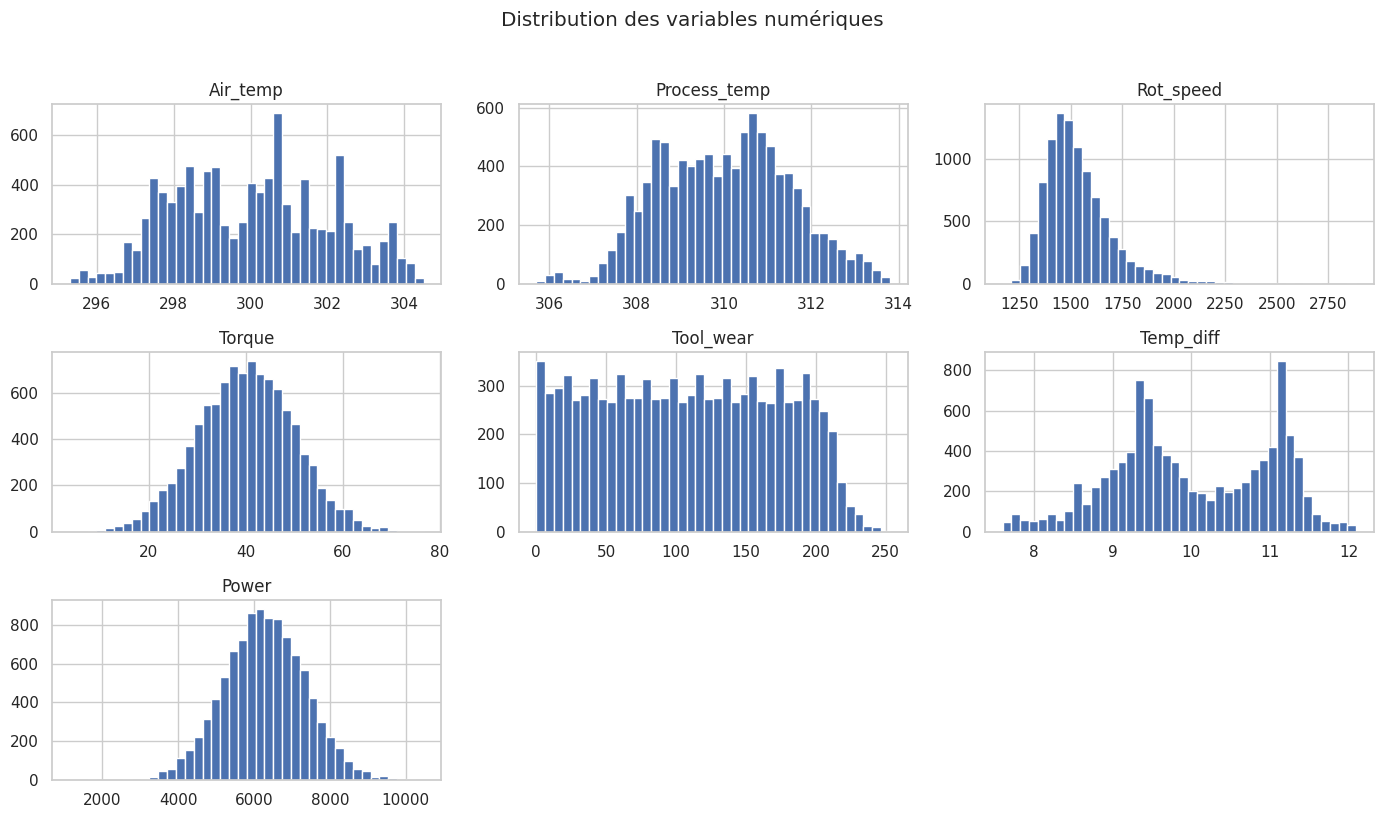

In [11]:
df[NUM_FEATURES].hist(bins=40, figsize=(14, 8), layout=(3, 3))
plt.suptitle("Distribution des variables numériques", y=1.02); plt.tight_layout(); plt.show()

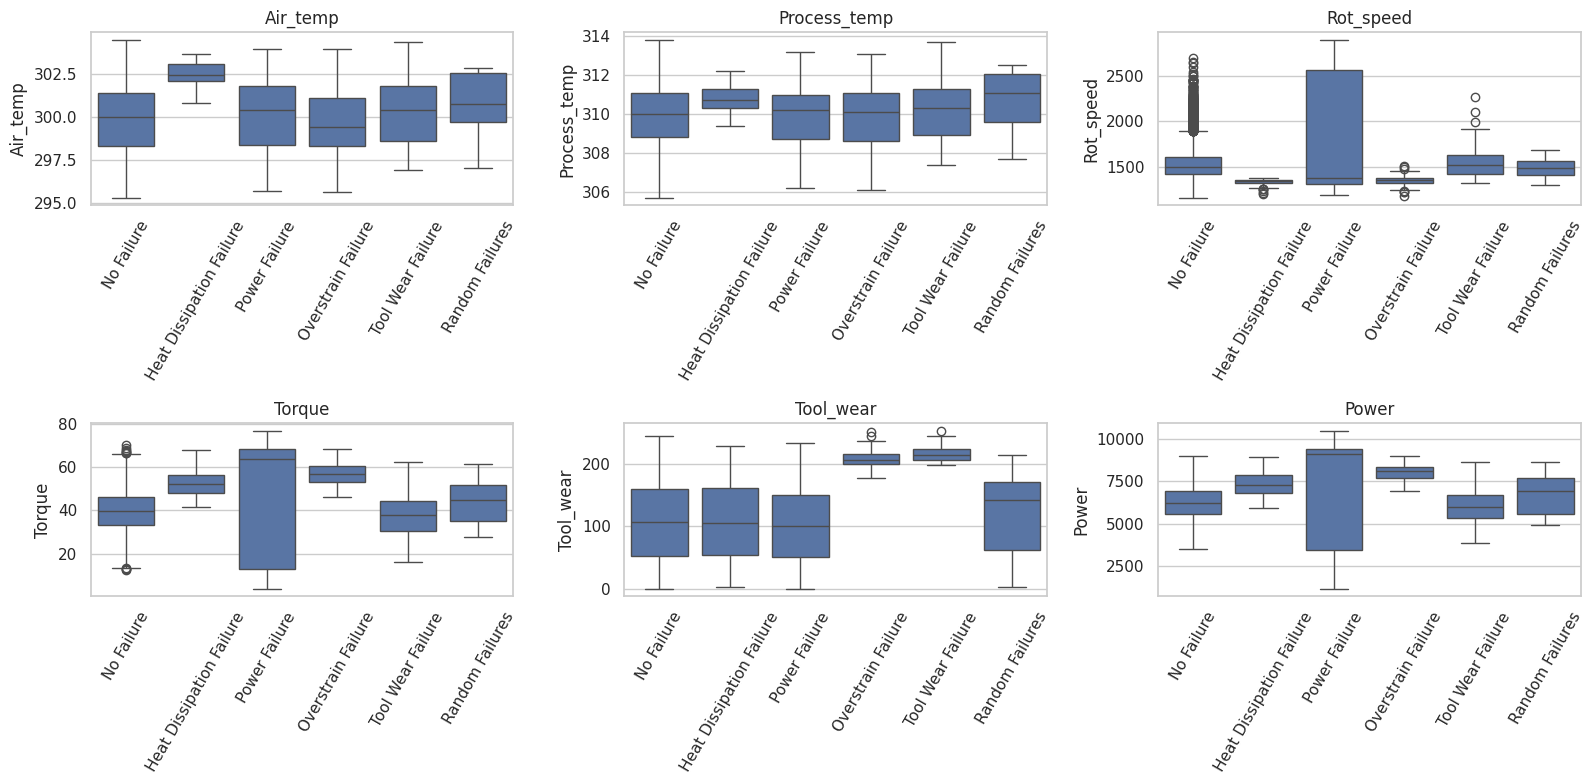

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear", "Power"]):
    sns.boxplot(data=df, x="Failure_Type", y=c, order=order, ax=ax)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60); ax.set_title(c)
plt.tight_layout(); plt.show()

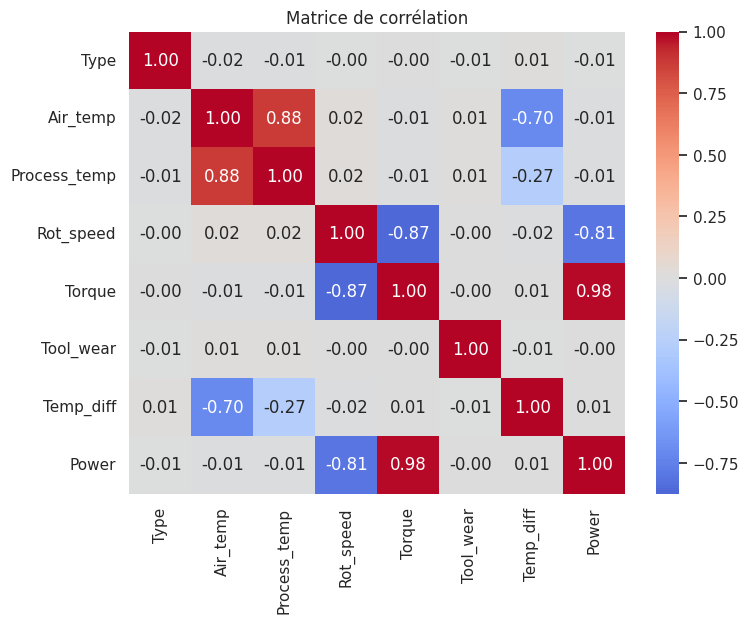

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation"); plt.show()

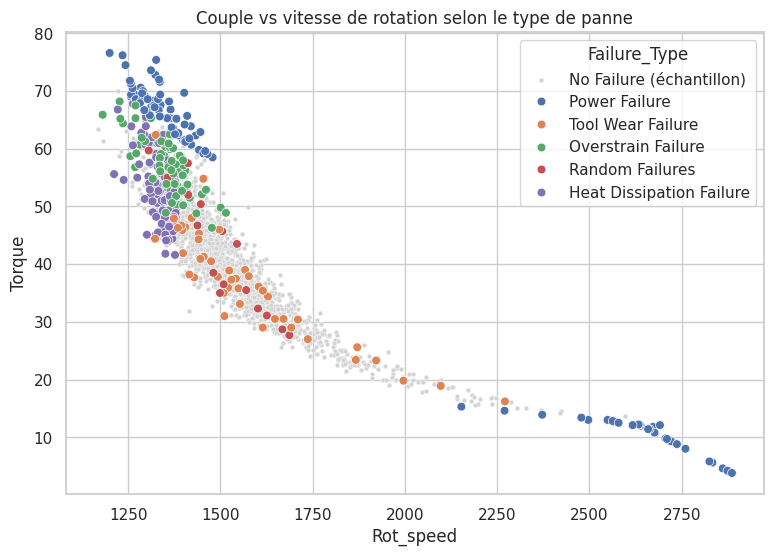

In [14]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df[df.Failure_Type == "No Failure"].sample(1500, random_state=SEED),
                x="Rot_speed", y="Torque", color="lightgrey", s=12, label="No Failure (échantillon)")
sns.scatterplot(data=df[df.Failure_Type != "No Failure"], x="Rot_speed", y="Torque",
                hue="Failure_Type", s=40)
plt.title("Couple vs vitesse de rotation selon le type de panne"); plt.show()

In [15]:
display(pd.crosstab(df["Type"].map({0: "L", 1: "M", 2: "H"}), df["Failure_Type"], normalize="index").round(4) * 100)

Failure_Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Type,,,,,,
H,0.80,97.60,0.10,0.50,0.40,0.60
L,1.23,95.95,1.22,0.98,0.20,0.42
M,1.00,97.29,0.13,1.04,0.07,0.47


3. Séparation train / validation / test, normalisation et augmentation

In [16]:
X = df[FEATURES].copy()
le = LabelEncoder()
y = le.fit_transform(df["Failure_Type"])
CLASS_NAMES = list(le.classes_)
N_CLASSES = len(CLASS_NAMES)
print(dict(enumerate(CLASS_NAMES)))

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15, stratify=y_trainval, random_state=SEED)

scaler = StandardScaler().fit(X_tr)          # ajusté sur le train uniquement
X_tr_s, X_val_s, X_test_s = (scaler.transform(a) for a in (X_tr, X_val, X_test))
print("train / val / test :", X_tr_s.shape, X_val_s.shape, X_test_s.shape)

{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Random Failures', 5: 'Tool Wear Failure'}
train / val / test : (6793, 8) (1199, 8) (1999, 8)


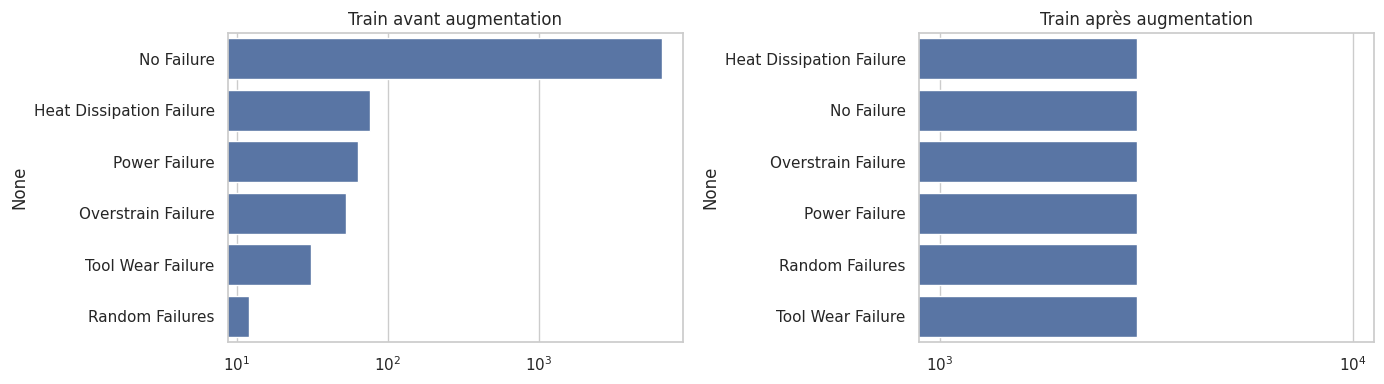

Après augmentation : {0: 3000, 1: 3000, 2: 3000, 3: 3000, 4: 3000, 5: 3000}


In [17]:
TARGET_N = 3000
counts = pd.Series(y_tr).value_counts()
over_strategy = {c: TARGET_N for c, n in counts.items() if n < TARGET_N}
under_strategy = {c: TARGET_N for c, n in counts.items() if n > TARGET_N}

def make_sampler():
    return ImbPipeline([
        ("smote", SMOTE(sampling_strategy=over_strategy, k_neighbors=3, random_state=SEED)),
        ("under", RandomUnderSampler(sampling_strategy=under_strategy, random_state=SEED)),
    ])

X_tr_aug, y_tr_aug = make_sampler().fit_resample(X_tr_s, y_tr)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=False)
for a, labels, title in zip(ax, (y_tr, y_tr_aug), ("Train avant augmentation", "Train après augmentation")):
    s = pd.Series(labels).map(dict(enumerate(CLASS_NAMES))).value_counts()
    sns.barplot(x=s.values, y=s.index, ax=a); a.set_title(title); a.set_xscale("log")
plt.tight_layout(); plt.show()
print("Après augmentation :", pd.Series(y_tr_aug).value_counts().sort_index().to_dict())

4. Architecture DNN / MLP avec PyTorch

In [18]:
class MLP(nn.Module):
    def __init__(self, in_dim, out_dim, hidden_layers=(64, 32), dropout=0.0,
                 batchnorm=False, activation="relu"):
        super().__init__()
        acts = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}
        layers, prev = [], in_dim
        for h in hidden_layers:
            layers.append(nn.Linear(prev, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(acts[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, out_dim))   # logits (softmax inclus dans CrossEntropyLoss)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden_layers=(64, 32), lr=1e-3, optimizer="adam", epochs=30,
                 batch_size=256, dropout=0.0, weight_decay=0.0, batchnorm=False,
                 activation="relu", patience=0, random_state=42):
        self.hidden_layers = hidden_layers
        self.lr = lr
        self.optimizer = optimizer
        self.epochs = epochs
        self.batch_size = batch_size
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.batchnorm = batchnorm
        self.activation = activation
        self.patience = patience
        self.random_state = random_state

    def _make_optimizer(self, params):
        o = self.optimizer
        if o == "adam":
            return torch.optim.Adam(params, lr=self.lr, weight_decay=self.weight_decay)
        if o == "adamw":
            return torch.optim.AdamW(params, lr=self.lr, weight_decay=self.weight_decay)
        if o == "sgd":
            return torch.optim.SGD(params, lr=self.lr, momentum=0.9, weight_decay=self.weight_decay)
        if o == "rmsprop":
            return torch.optim.RMSprop(params, lr=self.lr, weight_decay=self.weight_decay)
        raise ValueError(f"Optimiseur inconnu : {o}")

    def _to_tensors(self, X, y):
        Xt = torch.tensor(np.asarray(X, dtype=np.float32), device=DEVICE)
        yt = torch.tensor(np.searchsorted(self.classes_, np.asarray(y)), dtype=torch.long, device=DEVICE)
        return Xt, yt

    @torch.no_grad()
    def _evaluate(self, Xt, yt, criterion):
        self.model_.eval()
        out = self.model_(Xt)
        return criterion(out, yt).item(), (out.argmax(1) == yt).float().mean().item()

    def fit(self, X, y, val_set=None, test_set=None):
        torch.manual_seed(self.random_state); np.random.seed(self.random_state)
        X = np.asarray(X, dtype=np.float32); y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        Xt, yt = self._to_tensors(X, y)
        sets = {}
        if val_set is not None:
            sets["val"] = self._to_tensors(*val_set)
        if test_set is not None:
            sets["test"] = self._to_tensors(*test_set)

        self.model_ = MLP(X.shape[1], len(self.classes_), tuple(self.hidden_layers),
                          self.dropout, self.batchnorm, self.activation).to(DEVICE)
        criterion = nn.CrossEntropyLoss()
        opt = self._make_optimizer(self.model_.parameters())

        keys = ["train_loss", "train_acc"] + [f"{s}_{m}" for s in sets for m in ("loss", "acc")]
        self.history_ = {k: [] for k in keys}
        best_loss, best_state, wait = np.inf, None, 0
        n = len(Xt)

        for epoch in range(self.epochs):
            self.model_.train()
            perm = torch.randperm(n, device=DEVICE)
            tot_loss, correct, seen = 0.0, 0, 0
            for i in range(0, n, self.batch_size):
                idx = perm[i:i + self.batch_size]
                if len(idx) < 2:          # BatchNorm exige >= 2 échantillons
                    continue
                xb, yb = Xt[idx], yt[idx]
                opt.zero_grad()
                out = self.model_(xb)
                loss = criterion(out, yb)
                loss.backward()
                opt.step()
                tot_loss += loss.item() * len(idx)
                correct += (out.argmax(1) == yb).sum().item()
                seen += len(idx)
            self.history_["train_loss"].append(tot_loss / seen)
            self.history_["train_acc"].append(correct / seen)
            for name, (Xs, ys) in sets.items():
                l, a = self._evaluate(Xs, ys, criterion)
                self.history_[f"{name}_loss"].append(l)
                self.history_[f"{name}_acc"].append(a)

            # Early stopping sur la loss de VALIDATION (jamais sur le test)
            if self.patience > 0 and "val" in sets:
                v = self.history_["val_loss"][-1]
                if v < best_loss - 1e-5:
                    best_loss, wait = v, 0
                    best_state = copy.deepcopy(self.model_.state_dict())
                else:
                    wait += 1
                    if wait >= self.patience:
                        break
        if best_state is not None:
            self.model_.load_state_dict(best_state)
        return self

    @torch.no_grad()
    def predict_proba(self, X):
        self.model_.eval()
        Xt = torch.tensor(np.asarray(X, dtype=np.float32), device=DEVICE)
        return torch.softmax(self.model_(Xt), dim=1).cpu().numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

5. Recherche des hyper-paramètres avec GridSearchCV

In [20]:
pipe = ImbPipeline([
    ("smote", SMOTE(sampling_strategy=over_strategy, k_neighbors=3, random_state=SEED)),
    ("under", RandomUnderSampler(sampling_strategy=under_strategy, random_state=SEED)),
    ("clf", TorchMLPClassifier(random_state=SEED)),
])

param_grid = {
    "clf__hidden_layers": [(64, 32), (128, 64, 32)],
    "clf__lr": [1e-3, 1e-2],
    "clf__optimizer": ["adam", "sgd"],
    "clf__epochs": [30, 60],
}

grid = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
                    refit=False, n_jobs=1, verbose=2)
grid.fit(X_tr_s, y_tr)

print("\nMeilleur F1 macro (CV) :", round(grid.best_score_, 4))
print("Meilleurs paramètres  :", grid.best_params_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.001, clf__optimizer=adam; total time=   8.2s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.001, clf__optimizer=adam; total time=   3.6s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.001, clf__optimizer=adam; total time=   3.6s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.001, clf__optimizer=sgd; total time=   3.1s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.001, clf__optimizer=sgd; total time=   3.1s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.001, clf__optimizer=sgd; total time=   3.1s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.01, clf__optimizer=adam; total time=   3.4s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.01, clf__optimizer=adam; total time=   3.4s
[CV] END clf__epochs=30, clf__hidden_layers=(64, 32), clf__lr=0.01, clf_

In [21]:
cv_res = pd.DataFrame(grid.cv_results_)
cols = [c for c in cv_res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
cv_res[cols].sort_values("rank_test_score").head(10)

,param_clf__epochs,param_clf__hidden_layers,param_clf__lr,param_clf__optimizer,mean_test_score,std_test_score,rank_test_score
12,60,"(128, 64, 32)",0.001,adam,0.546460,0.019694,1
15,60,"(128, 64, 32)",0.010,sgd,0.540392,0.012110,2
2,30,"(64, 32)",0.010,adam,0.537068,0.004105,3
4,30,"(128, 64, 32)",0.001,adam,0.536817,0.016110,4
10,60,"(64, 32)",0.010,adam,0.532732,0.025697,5
8,60,"(64, 32)",0.001,adam,0.530211,0.021119,6
6,30,"(128, 64, 32)",0.010,adam,0.522602,0.012621,7
14,60,"(128, 64, 32)",0.010,adam,0.521392,0.041329,8
7,30,"(128, 64, 32)",0.010,sgd,0.518594,0.012339,9
11,60,"(64, 32)",0.010,sgd,0.508335,0.024227,10


In [22]:
best_params = {k.replace("clf__", ""): v for k, v in grid.best_params_.items()}
best_params

{'epochs': 60,
 'hidden_layers': (128, 64, 32),
 'lr': 0.001,
 'optimizer': 'adam'}

6. Entraînement du modèle de référence et courbes Loss / Accuracy

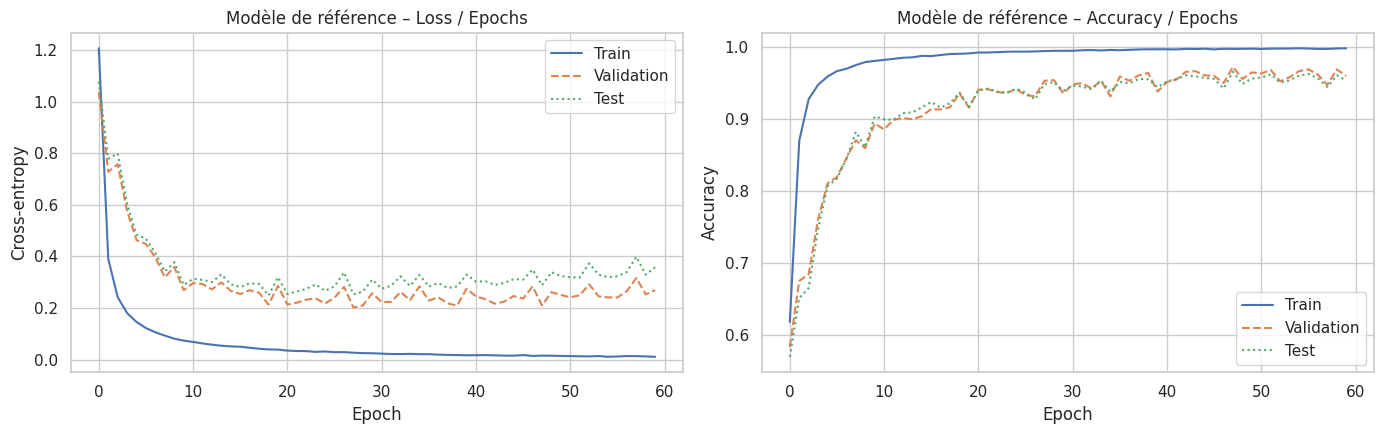

In [23]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for key, label, ls in [("train", "Train", "-"), ("val", "Validation", "--"), ("test", "Test", ":")]:
        if f"{key}_loss" in h:
            ax[0].plot(h[f"{key}_loss"], ls, label=label)
            ax[1].plot(h[f"{key}_acc"], ls, label=label)
    ax[0].set(title=f"{title} – Loss / Epochs", xlabel="Epoch", ylabel="Cross-entropy")
    ax[1].set(title=f"{title} – Accuracy / Epochs", xlabel="Epoch", ylabel="Accuracy")
    for a in ax: a.legend()
    plt.tight_layout(); plt.show()

base_model = TorchMLPClassifier(**best_params, random_state=SEED).fit(
    X_tr_aug, y_tr_aug, val_set=(X_val_s, y_val), test_set=(X_test_s, y_test))
plot_history(base_model.history_, "Modèle de référence")

7. Métriques (train et test)

In [24]:
def full_metrics(model, X, y):
    y_pred = model.predict(X)
    cm = confusion_matrix(y, y_pred, labels=np.arange(N_CLASSES))
    TP = np.diag(cm); FP = cm.sum(0) - TP; FN = cm.sum(1) - TP; TN = cm.sum() - (TP + FP + FN)
    spec = TN / np.maximum(TN + FP, 1)
    return {
        "accuracy": accuracy_score(y, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "precision_macro": precision_score(y, y_pred, average="macro", zero_division=0),
        "sensibilité_macro (recall)": recall_score(y, y_pred, average="macro", zero_division=0),
        "spécificité_macro": spec.mean(),
        "f1_macro": f1_score(y, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y, y_pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y, y_pred),
    }

metrics_base = pd.DataFrame({
    "Train": full_metrics(base_model, X_tr_s, y_tr),
    "Test": full_metrics(base_model, X_test_s, y_test),
}).round(4)
metrics_base

,Train,Test
accuracy,0.9745,0.9530
balanced_accuracy,0.9956,0.5670
precision_macro,0.6394,0.4707
sensibilité_macro (recall),0.9956,0.5670
spécificité_macro,0.9957,0.9439
f1_macro,0.7438,0.5081
f1_weighted,0.9795,0.9614
MCC,0.7538,0.5107


                          precision    recall  f1-score   support

Heat Dissipation Failure      0.556     0.909     0.690        22
              No Failure      0.989     0.963     0.976      1929
      Overstrain Failure      0.688     0.688     0.688        16
           Power Failure      0.593     0.842     0.696        19
         Random Failures      0.000     0.000     0.000         4
       Tool Wear Failure      0.000     0.000     0.000         9

                accuracy                          0.953      1999
               macro avg      0.471     0.567     0.508      1999
            weighted avg      0.971     0.953     0.961      1999



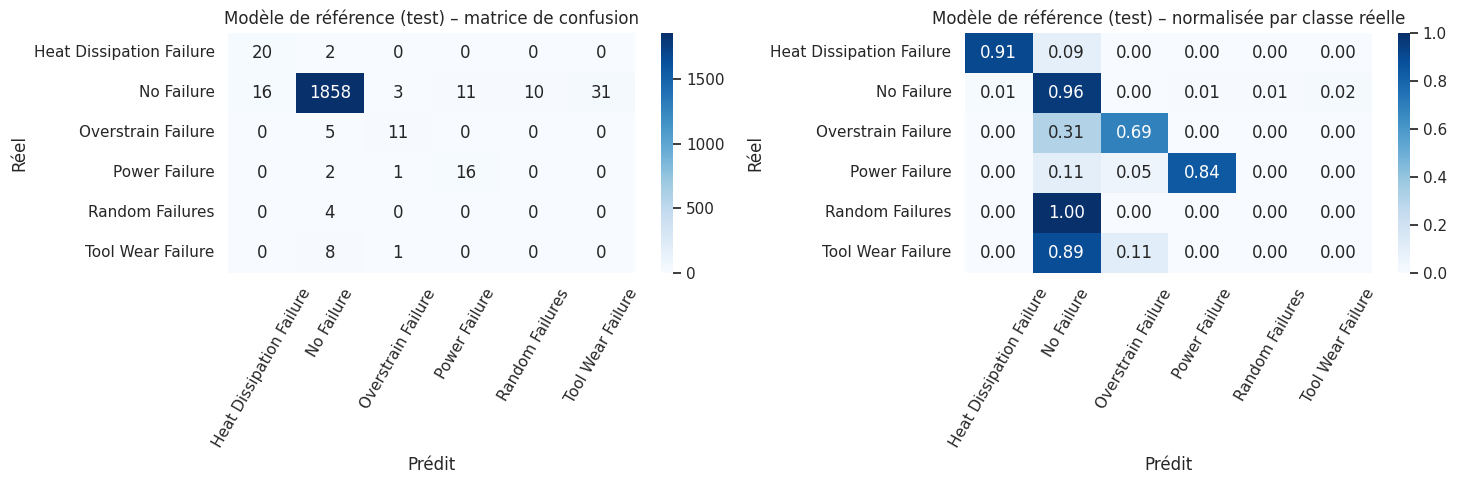

In [25]:
def report_and_cm(model, X, y, title):
    y_pred = model.predict(X)
    print(classification_report(y, y_pred, labels=np.arange(N_CLASSES),
                                target_names=CLASS_NAMES, zero_division=0, digits=3))
    cm = confusion_matrix(y, y_pred, labels=np.arange(N_CLASSES))
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
    ax[0].set(title=f"{title} – matrice de confusion", xlabel="Prédit", ylabel="Réel")
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
    ax[1].set(title=f"{title} – normalisée par classe réelle", xlabel="Prédit", ylabel="Réel")
    for a in ax: a.tick_params(axis="x", rotation=60)
    plt.tight_layout(); plt.show()

report_and_cm(base_model, X_test_s, y_test, "Modèle de référence (test)")

8. Techniques de régularisation et comparaison

In [26]:
experiments = {
    "Référence": {},
    "+ Dropout 0.3": {"dropout": 0.3},
    "+ L2 (1e-3)": {"weight_decay": 1e-3},
    "+ BatchNorm": {"batchnorm": True},
    "+ Early stopping": {"patience": 10, "epochs": 100},
    "Combinaison": {"dropout": 0.2, "weight_decay": 1e-4, "batchnorm": True, "patience": 10, "epochs": 100},
}

models, histories, rows = {}, {}, []
for name, extra in experiments.items():
    params = {**best_params, **extra}
    m = TorchMLPClassifier(**params, random_state=SEED).fit(
        X_tr_aug, y_tr_aug, val_set=(X_val_s, y_val), test_set=(X_test_s, y_test))
    models[name], histories[name] = m, m.history_
    tr, va, te = (full_metrics(m, X_tr_s, y_tr), full_metrics(m, X_val_s, y_val), full_metrics(m, X_test_s, y_test))
    rows.append({
        "Modèle": name,
        "Epochs effectifs": len(m.history_["train_loss"]),
        "F1 macro train": tr["f1_macro"], "F1 macro val": va["f1_macro"], "F1 macro test": te["f1_macro"],
        "Écart F1 train-test": tr["f1_macro"] - te["f1_macro"],
        "Accuracy test": te["accuracy"], "Sensibilité test": te["sensibilité_macro (recall)"],
        "Spécificité test": te["spécificité_macro"],
    })
    print(f"{name:20s} terminé ({rows[-1]['Epochs effectifs']} epochs)")

comparison = pd.DataFrame(rows).set_index("Modèle").round(4)
comparison

Référence            terminé (60 epochs)
+ Dropout 0.3        terminé (60 epochs)
+ L2 (1e-3)          terminé (60 epochs)
+ BatchNorm          terminé (60 epochs)
+ Early stopping     terminé (38 epochs)
Combinaison          terminé (73 epochs)


,Epochs effectifs,F1 macro train,F1 macro val,F1 macro test,Écart F1 train-test,Accuracy test,Sensibilité test,Spécificité test
Modèle,,,,,,,,
Référence,60,0.7438,0.5506,0.5081,0.2357,0.9530,0.5670,0.9439
+ Dropout 0.3,60,0.5622,0.5009,0.4798,0.0823,0.9130,0.6538,0.9578
+ L2 (1e-3),60,0.6512,0.5303,0.5215,0.1297,0.9430,0.6406,0.9583
+ BatchNorm,60,0.7468,0.5732,0.5288,0.2180,0.9525,0.6260,0.9576
+ Early stopping,38,0.7052,0.5767,0.5356,0.1695,0.9480,0.5901,0.9476
Combinaison,73,0.6351,0.5222,0.5292,0.1059,0.9350,0.6576,0.9615


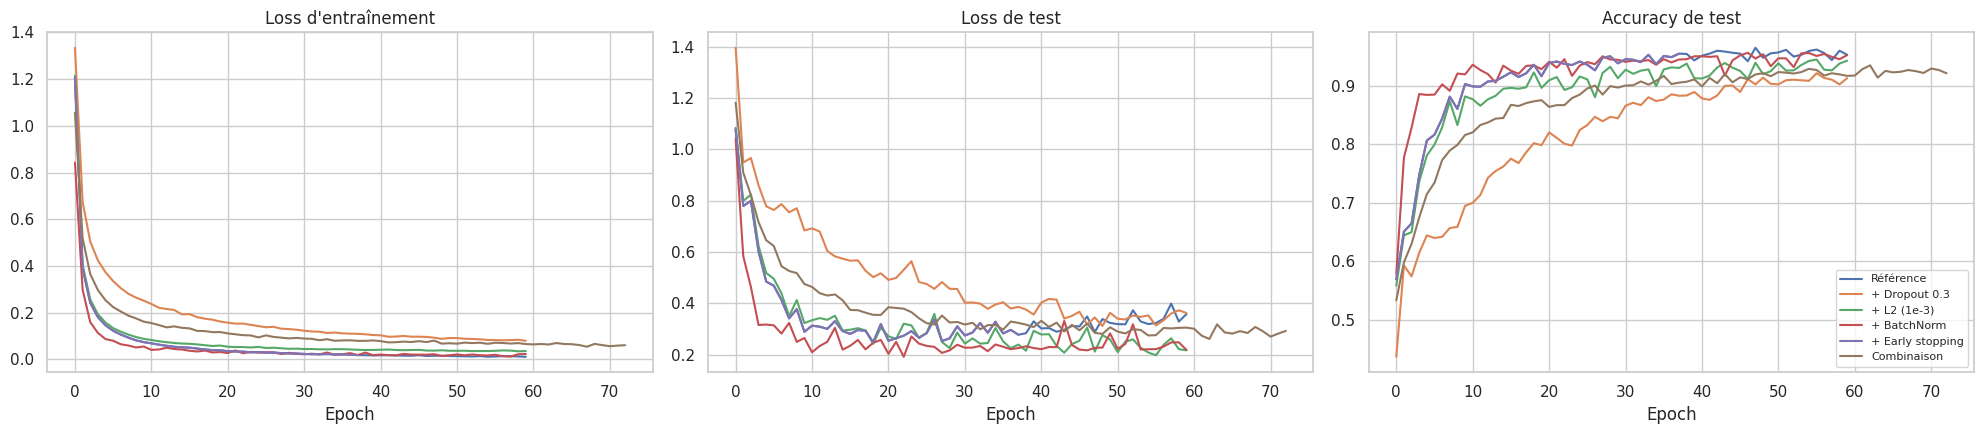

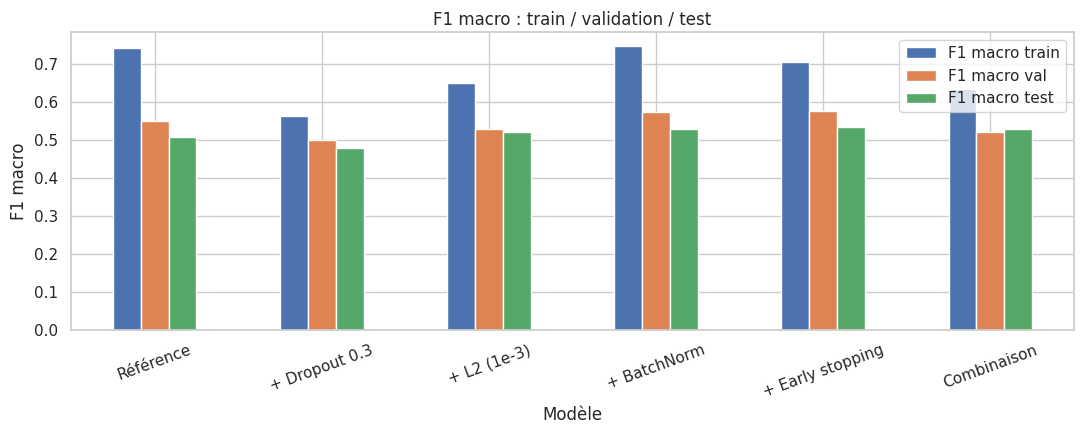

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for name, h in histories.items():
    ax[0].plot(h["train_loss"], label=name)
    ax[1].plot(h["test_loss"], label=name)
    ax[2].plot(h["test_acc"], label=name)
ax[0].set(title="Loss d'entraînement", xlabel="Epoch")
ax[1].set(title="Loss de test", xlabel="Epoch")
ax[2].set(title="Accuracy de test", xlabel="Epoch")
ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

comparison[["F1 macro train", "F1 macro val", "F1 macro test"]].plot.bar(figsize=(11, 4.5), rot=20)
plt.title("F1 macro : train / validation / test"); plt.ylabel("F1 macro"); plt.tight_layout(); plt.show()

Meilleur modèle (selon le F1 macro de validation) : + Early stopping


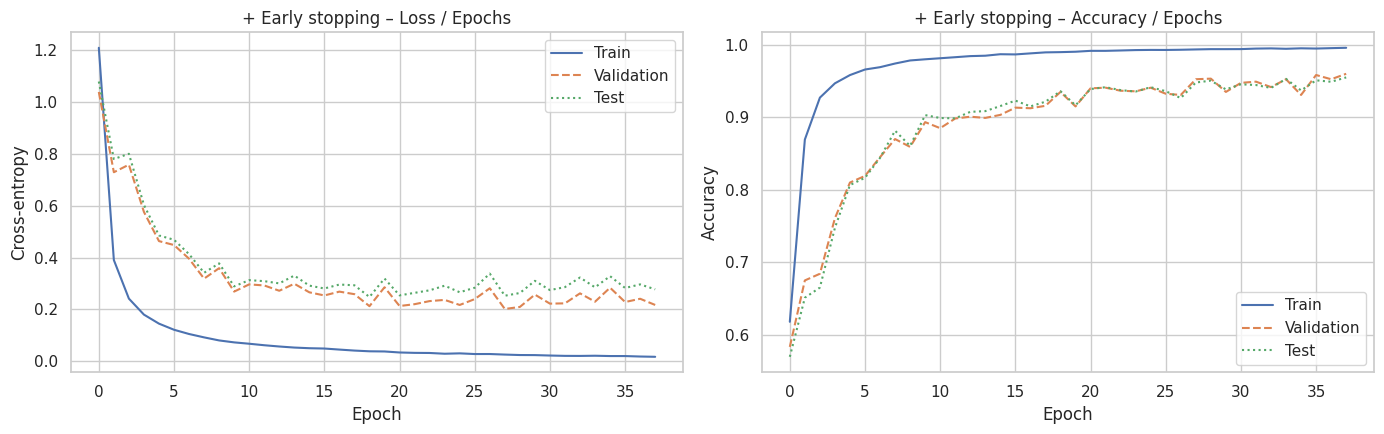

,Train,Test
accuracy,0.9657,0.9480
balanced_accuracy,0.9915,0.5901
precision_macro,0.6216,0.4995
sensibilité_macro (recall),0.9915,0.5901
spécificité_macro,0.9936,0.9476
f1_macro,0.7052,0.5356
f1_weighted,0.9750,0.9602
MCC,0.7010,0.5029


In [28]:
best_name = comparison["F1 macro val"].idxmax()
print("Meilleur modèle (selon le F1 macro de validation) :", best_name)
plot_history(histories[best_name], f"{best_name}")
pd.DataFrame({
    "Train": full_metrics(models[best_name], X_tr_s, y_tr),
    "Test": full_metrics(models[best_name], X_test_s, y_test),
}).round(4)

                          precision    recall  f1-score   support

Heat Dissipation Failure      0.588     0.909     0.714        22
              No Failure      0.990     0.957     0.973      1929
      Overstrain Failure      0.682     0.938     0.789        16
           Power Failure      0.737     0.737     0.737        19
         Random Failures      0.000     0.000     0.000         4
       Tool Wear Failure      0.000     0.000     0.000         9

                accuracy                          0.948      1999
               macro avg      0.499     0.590     0.536      1999
            weighted avg      0.974     0.948     0.960      1999



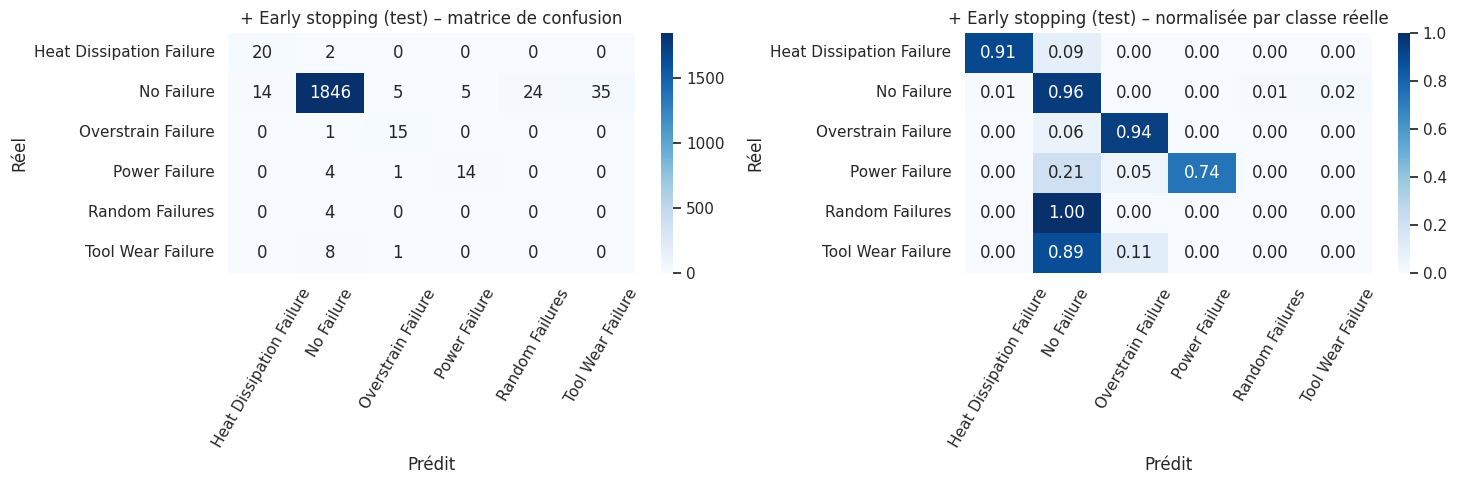

In [29]:
report_and_cm(models[best_name], X_test_s, y_test, f"{best_name} (test)")